### This notebook will be used to see how well detections models perform on this dataset.

In [21]:
import ultralytics
import scipy
import pandas as pd
from ultralytics import YOLO
from scipy.io import loadmat
import pandas as pd
import os
import numpy as np
from torchmetrics.detection.mean_ap import MeanAveragePrecision
import torch


In [4]:
frame_train_path = "C:\\Users\\saadq\\Documents\\Unibo AI\\Semester 03\\ML4CV\\ML4CV-Assignment\\data\\archive\\frame_train.mat"
ID_train_path = "C:\\Users\\saadq\\Documents\\Unibo AI\\Semester 03\\ML4CV\\ML4CV-Assignment\\data\\archive\\ID_train.mat"

frame_test_path = "C:\\Users\\saadq\\Documents\\Unibo AI\\Semester 03\\ML4CV\\ML4CV-Assignment\\data\\archive\\frame_test.mat"
ID_test_path = "C:\\Users\\saadq\\Documents\\Unibo AI\\Semester 03\\ML4CV\\ML4CV-Assignment\\data\\archive\\ID_test.mat"

frames_dir = "C:\\Users\\saadq\\Documents\\Unibo AI\\Semester 03\\ML4CV\\ML4CV-Assignment\\data\\archive\\frames\\"
annotations_dir = "C:\\Users\\saadq\\Documents\\Unibo AI\\Semester 03\\ML4CV\\ML4CV-Assignment\\data\\archive\\annotations\\"


data_frame_train = loadmat(frame_train_path)
print(data_frame_train.keys())

data_ID_train = loadmat(ID_train_path)
print(data_ID_train.keys())

data_frame_test = loadmat(frame_test_path)
print(data_frame_test.keys())

data_ID_test = loadmat(ID_test_path)
print(data_ID_test.keys())

dict_keys(['__header__', '__version__', '__globals__', 'img_index_train'])
dict_keys(['__header__', '__version__', '__globals__', 'ID_train'])
dict_keys(['__header__', '__version__', '__globals__', 'img_index_test'])
dict_keys(['__header__', '__version__', '__globals__', 'ID_test2'])


In [5]:
df_img_index = pd.DataFrame(data_frame_train["img_index_train"].reshape(-1, 1), columns=["image_index_train"])
df_ID_train = pd.DataFrame(data_ID_train["ID_train"].reshape(-1, 1), columns=["ID_train"])
df_train = pd.concat([df_img_index, df_ID_train], axis=1)


df_img_index_test = pd.DataFrame(data_frame_test["img_index_test"].reshape(-1, 1), columns=["image_index_test"])
df_ID_test = pd.DataFrame(data_ID_test["ID_test2"].reshape(-1, 1), columns=["ID_test"])
df_test = pd.concat([df_img_index_test, df_ID_test], axis=1)


In [6]:
df_train.head()

,image_index_train,ID_train
0,[c1s1_000151],1.0
1,[c1s1_000376],2.0
2,[c1s1_000401],3.0
3,[c1s1_000426],4.0
4,[c1s1_000451],5.0


In [7]:
df_train["image_index_train"] = df_train["image_index_train"].apply(lambda x: x[0])
df_train["image_path"] = df_train["image_index_train"].apply(lambda x: x.replace("[", "").replace("]", "") + ".jpg").apply(lambda x : os.path.join(frames_dir, x))

def safe_load(row):
    path = os.path.join(annotations_dir, row["image_index_train"] + ".jpg.mat")

    if not os.path.exists(path):
        print("MISSING FILE:", path)
        return None

    data = loadmat(path)

    if "box_new" not in data:
        print("NO box_new:", path, data.keys())
        return None

    return data["box_new"]


df_train["annotations"] = df_train.apply(safe_load, axis=1)

NO box_new: C:\Users\saadq\Documents\Unibo AI\Semester 03\ML4CV\ML4CV-Assignment\data\archive\annotations\c1s2_006041.jpg.mat dict_keys(['__header__', '__version__', '__globals__', 'anno_file'])
NO box_new: C:\Users\saadq\Documents\Unibo AI\Semester 03\ML4CV\ML4CV-Assignment\data\archive\annotations\c2s1_049776.jpg.mat dict_keys(['__header__', '__version__', '__globals__', 'anno_file'])
NO box_new: C:\Users\saadq\Documents\Unibo AI\Semester 03\ML4CV\ML4CV-Assignment\data\archive\annotations\c6s1_036851.jpg.mat dict_keys(['__header__', '__version__', '__globals__', 'anno_file'])


### Lets start with a small dataframe

In [25]:
df_train_small = df_train.sample(n=len(df_train), random_state=224)

### Using pretrained yolov8n for detection.

In [26]:
model = YOLO("yolov8n.pt")
image_paths = df_train_small["image_path"].tolist()
results = model(image_paths) # ← pass list of paths directly to model.

detection_results = {}

for path, result in zip(image_paths, results):  # ← use original path
    if result.boxes is None:
        detection_results[path] = []
        continue

    xyxy  = result.boxes.xyxy
    confs = result.boxes.conf
    names = np.array([result.names[cls.item()] for cls in result.boxes.cls.int()])

    mask = names == "person"

    detection_results[path] = [
    [box[0], box[1], box[2]-box[0], box[3]-box[1], float(conf)]  # x, y, w, h, conf
    for box, conf in zip(xyxy[mask].cpu().numpy(), confs[mask].cpu().numpy())
]

MemoryError: 

In [10]:
detection_df = pd.DataFrame({
    "image_path": list(detection_results.keys()),
    "detections": list(detection_results.values())
})

In [11]:
detection_df.head()

,image_path,detections
0,C:\Users\saadq\Documents\Unibo AI\Semester 03\...,"[[1344.1586, 318.48047, 69.89685, 233.50488, 0..."
1,C:\Users\saadq\Documents\Unibo AI\Semester 03\...,"[[1698.5409, 275.7777, 85.36084, 260.80444, 0...."
2,C:\Users\saadq\Documents\Unibo AI\Semester 03\...,"[[90.32872, 272.88702, 188.859, 374.3604, 0.88..."
3,C:\Users\saadq\Documents\Unibo AI\Semester 03\...,"[[23.806927, 92.79279, 84.89859, 183.11649, 0...."
4,C:\Users\saadq\Documents\Unibo AI\Semester 03\...,"[[561.5462, 417.82828, 257.20898, 498.36526, 0..."


In [12]:
# Merge with original df to get annotations
final_df = df_train_small.merge(detection_df, on="image_path", how="left")

### Annotations are in format [[id, x, y, w , h] ..] whereas detection are in form [[x, y, w, h, conf] ..]

In [13]:
final_df.head()

,image_index_train,ID_train,image_path,annotations,detections
0,c4s2_007817,NaN,C:\Users\saadq\Documents\Unibo AI\Semester 03\...,"[[298.0, 1341.882289416847, 311.9038876889847,...","[[1344.1586, 318.48047, 69.89685, 233.50488, 0..."
1,c4s1_059732,NaN,C:\Users\saadq\Documents\Unibo AI\Semester 03\...,"[[-2.0, 799.6328144747459, 317.3864598268233, ...","[[1698.5409, 275.7777, 85.36084, 260.80444, 0...."
2,c3s1_063942,NaN,C:\Users\saadq\Documents\Unibo AI\Semester 03\...,"[[-2.0, 1269.5712742980559, 421.53671706263503...","[[90.32872, 272.88702, 188.859, 374.3604, 0.88..."
3,c6s1_004676,NaN,C:\Users\saadq\Documents\Unibo AI\Semester 03\...,"[[3.0, 30.20194384449269, 93.18250539956802, 7...","[[23.806927, 92.79279, 84.89859, 183.11649, 0...."
4,c3s1_078317,NaN,C:\Users\saadq\Documents\Unibo AI\Semester 03\...,"[[1.0, 1353.610151187905, 416.87149028077715, ...","[[561.5462, 417.82828, 257.20898, 498.36526, 0..."


In [14]:
def compute_iou(box1, box2):
    """Both boxes in [x_topleft, y_topleft, w, h] format"""
    x1, y1 = max(box1[0], box2[0]), max(box1[1], box2[1])
    x2, y2 = min(box1[0]+box1[2], box2[0]+box2[2]), min(box1[1]+box1[3], box2[1]+box2[3])

    inter = max(0, x2 - x1) * max(0, y2 - y1)
    union = box1[2]*box1[3] + box2[2]*box2[3] - inter
    return inter / union if union > 0 else 0


def match_detections(annotations, detections, iou_threshold=0.5):
    """
    Returns a list of dicts, one per annotation:
      - annotation: the GT box
      - matched_detection: the detection box+conf if matched, else None
      - iou: the iou score if matched, else 0
    """
    results = []
    used = set()  # track already-matched detections

    for ann in annotations:
        best_iou, best_idx = 0, -1

        for i, det in enumerate(detections):
            if i in used:
                continue
            iou = compute_iou(ann[1:5], det[:4])  # ann[1:5] strips class id, det[:4] strips conf
            if iou > best_iou:
                best_iou, best_idx = iou, i

        if best_iou >= iou_threshold:
            used.add(best_idx)
            results.append({
                "annotation": ann,
                "matched_detection": detections[best_idx],
                "iou": best_iou
            })
        else:
            results.append({
                "annotation": ann,
                "matched_detection": None,
                "iou": 0
            })

    return results



In [15]:

# Apply to dataframe
iou_threshold = 0.5

final_df["matches"] = final_df.apply(
    lambda row: match_detections(row["annotations"], row["detections"], iou_threshold),
    axis=1
)

# Convenience columns
final_df["n_annotations"] = final_df["annotations"].apply(len)
final_df["n_matched"]     = final_df["matches"].apply(lambda m: sum(1 for x in m if x["matched_detection"] is not None))
final_df["n_missed"]      = final_df["n_annotations"] - final_df["n_matched"]

In [16]:
final_df.head()

,image_index_train,ID_train,image_path,annotations,detections,matches,n_annotations,n_matched,n_missed
0,c4s2_007817,NaN,C:\Users\saadq\Documents\Unibo AI\Semester 03\...,"[[298.0, 1341.882289416847, 311.9038876889847,...","[[1344.1586, 318.48047, 69.89685, 233.50488, 0...","[{'annotation': [298.0, 1341.882289416847, 311...",2,1,1
1,c4s1_059732,NaN,C:\Users\saadq\Documents\Unibo AI\Semester 03\...,"[[-2.0, 799.6328144747459, 317.3864598268233, ...","[[1698.5409, 275.7777, 85.36084, 260.80444, 0....","[{'annotation': [-2.0, 799.6328144747459, 317....",3,3,0
2,c3s1_063942,NaN,C:\Users\saadq\Documents\Unibo AI\Semester 03\...,"[[-2.0, 1269.5712742980559, 421.53671706263503...","[[90.32872, 272.88702, 188.859, 374.3604, 0.88...","[{'annotation': [-2.0, 1269.5712742980559, 421...",6,2,4
3,c6s1_004676,NaN,C:\Users\saadq\Documents\Unibo AI\Semester 03\...,"[[3.0, 30.20194384449269, 93.18250539956802, 7...","[[23.806927, 92.79279, 84.89859, 183.11649, 0....","[{'annotation': [3.0, 30.20194384449269, 93.18...",1,1,0
4,c3s1_078317,NaN,C:\Users\saadq\Documents\Unibo AI\Semester 03\...,"[[1.0, 1353.610151187905, 416.87149028077715, ...","[[561.5462, 417.82828, 257.20898, 498.36526, 0...","[{'annotation': [1.0, 1353.610151187905, 416.8...",6,6,0


In [17]:
final_df["annotations"].iloc[0]

array([[        298,      1341.9,       311.9,      83.974,      249.59],
       [        307,      1601.4,      310.54,      40.684,      122.36]])

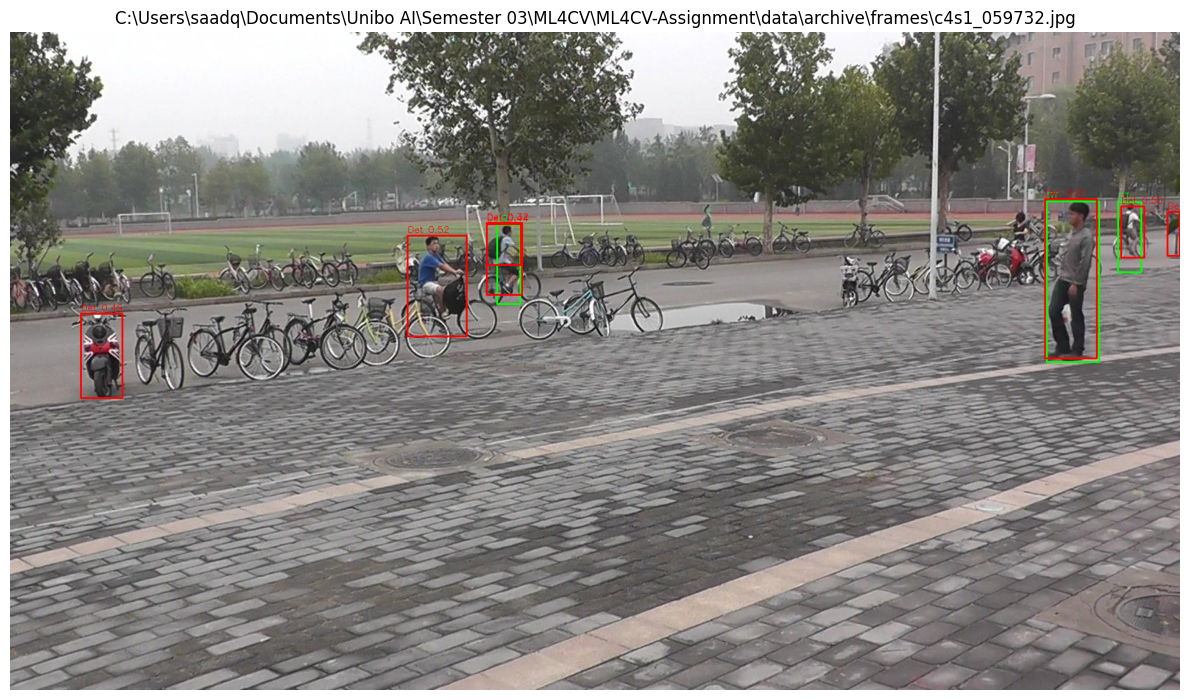

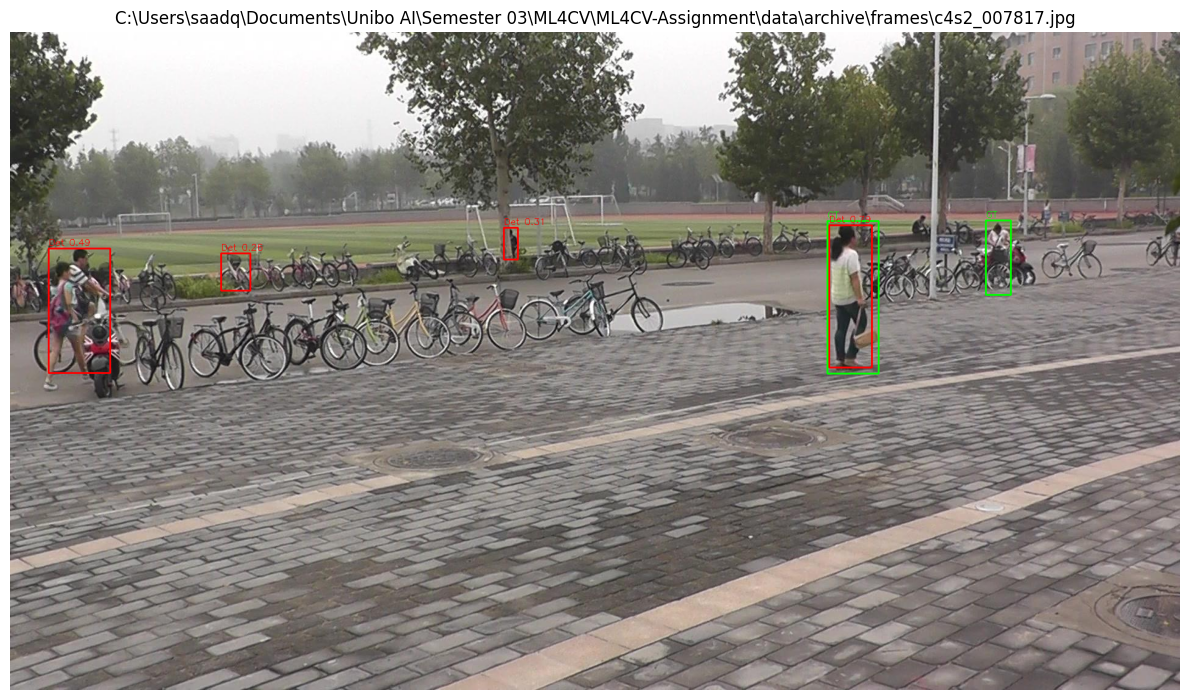

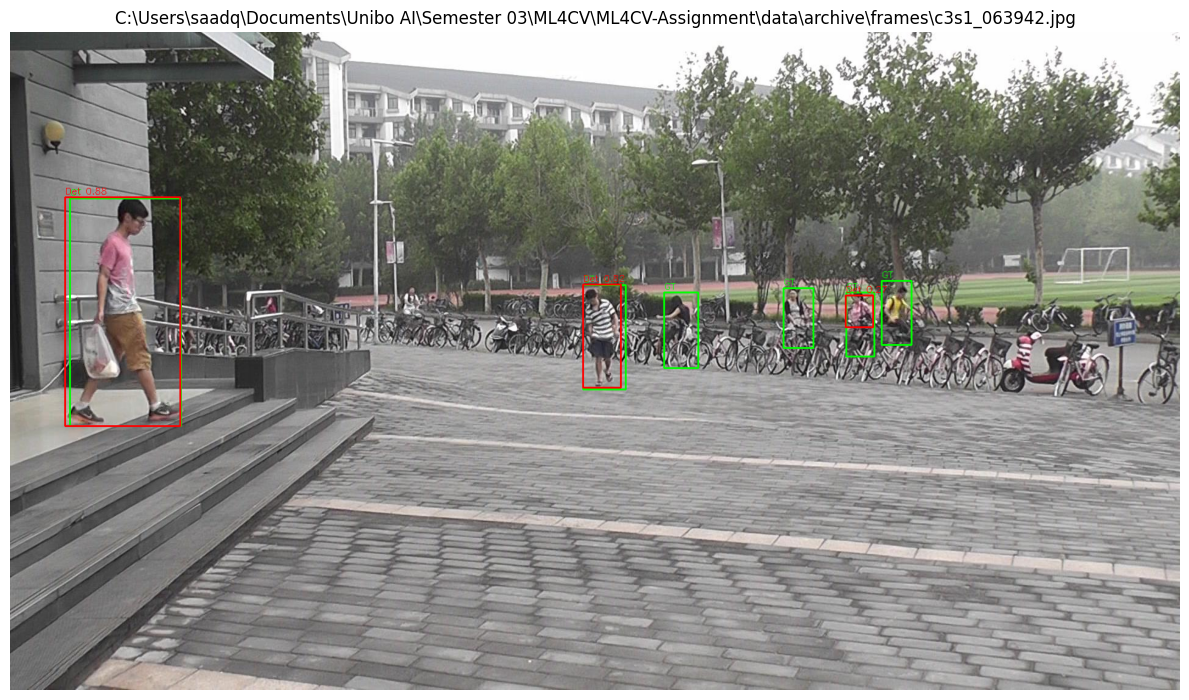

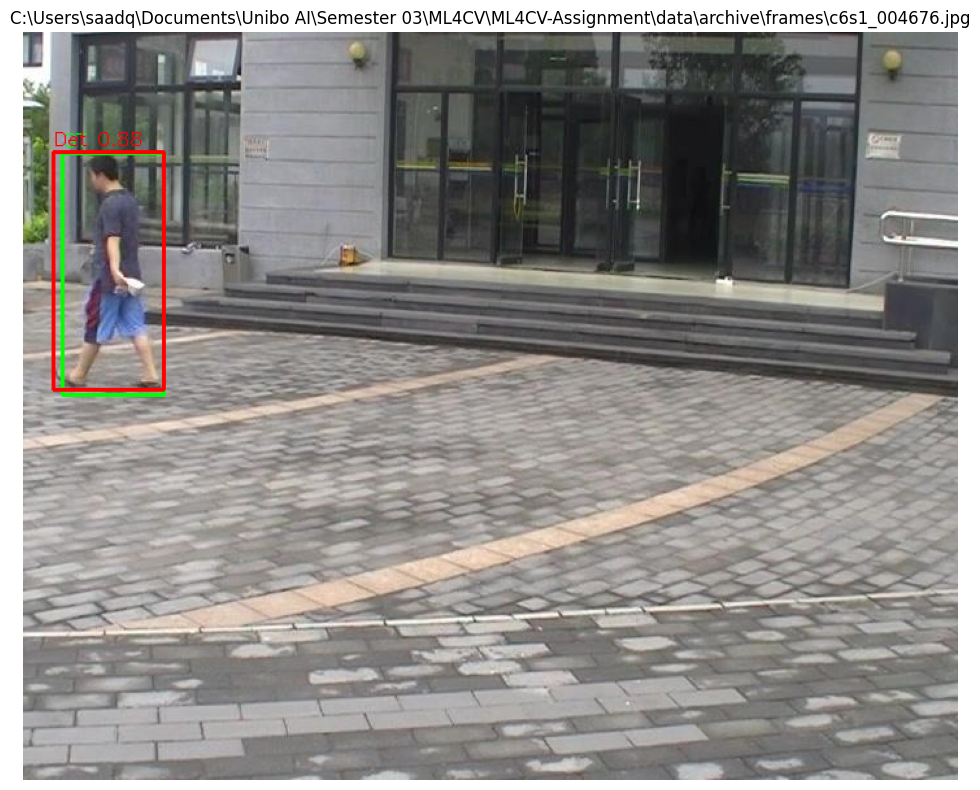

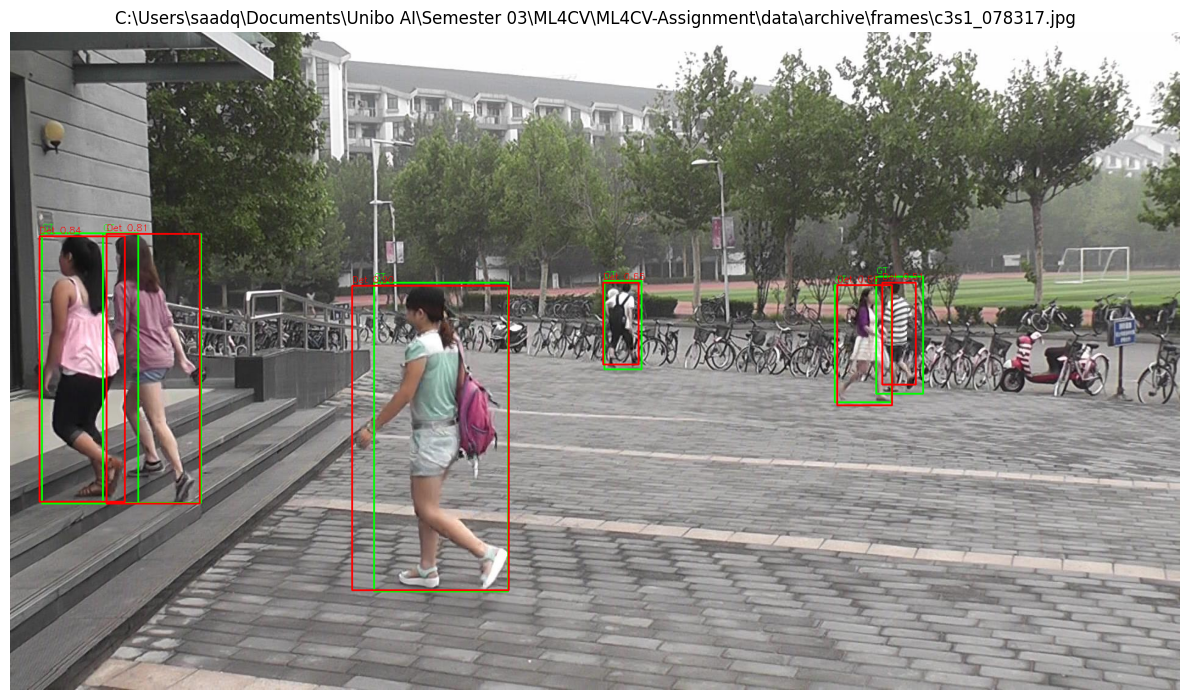

In [23]:
import cv2
import matplotlib.pyplot as plt

def plot_detections(image_path, annotations, detections, iou_threshold=0.5):
    img = cv2.imread(image_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    h, w = img.shape[:2]

    # draw annotations in green
    for ann in annotations:
        _, x, y, bw, bh = ann
        x1, y1 = int(x), int(y)              # already top-left
        x2, y2 = int(x + bw), int(y + bh)
        cv2.rectangle(img, (x1, y1), (x2, y2), (0, 255, 0), 2)
        cv2.putText(img, "GT", (x1, y1 - 5), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 0), 1)

    # draw detections in red
    for det in detections:
        x, y, bw, bh, conf = det
        x1, y1 = int(x), int(y)              # already top-left
        x2, y2 = int(x + bw), int(y + bh)
        cv2.rectangle(img, (x1, y1), (x2, y2), (255, 0, 0), 2)
        cv2.putText(img, f"Det {conf:.2f}", (x1, y1 - 5), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 0, 0), 1)

    plt.figure(figsize=(12, 8))
    plt.imshow(img)
    plt.title(image_path.split("/")[-1])
    plt.axis("off")
    plt.tight_layout()
    plt.show()


# plot for each row
for _, row in final_df.sample(n=5).iterrows():
    plot_detections(row["image_path"], row["annotations"], row["detections"], iou_threshold=0.5)

In [22]:

metric = MeanAveragePrecision(iou_type="bbox", box_format="xywh")

for _, row in final_df.iterrows():
    preds = [
        {
            "boxes": torch.tensor([[d[0], d[1], d[2], d[3]] for d in row["detections"]], dtype=torch.float32),
            "scores": torch.tensor([d[4] for d in row["detections"]], dtype=torch.float32),
            "labels": torch.zeros(len(row["detections"]), dtype=torch.int64),  # all person=0
        }
    ]
    targets = [
        {
            "boxes": torch.tensor([[a[1], a[2], a[3], a[4]] for a in row["annotations"]], dtype=torch.float32),
            "labels": torch.zeros(len(row["annotations"]), dtype=torch.int64),  # all person=0
        }
    ]
    metric.update(preds, targets)

results = metric.compute()
print(f"mAP@0.5:      {results['map_50']:.4f}")
print(f"mAP@0.5:0.95: {results['map']:.4f}")

mAP@0.5:      0.7004
mAP@0.5:0.95: 0.4534
